# IPL InsightX - Exploratory Data Analysis
**IPL Performance Analysis Using Data Analytics** (Data Science and Ecosystem - theme: Analytics)

## 1. Project introduction
This notebook explores historical Indian Premier League (IPL) match and ball-by-ball data. It uses the **same cleaning
functions and metric definitions** as the Streamlit application (`src/` folder), so the numbers here match the dashboard.

Every number printed below is calculated from the dataset in `data/`. Nothing is typed in by hand.

## 2. Problem statement
Raw cricket data has thousands of rows and several traps (tied matches, abandoned matches, renamed teams, extras that are
not the batter's or bowler's fault). We need a reliable way to turn it into trustworthy statistics about teams, players,
toss decisions, venues and seasons.

## 3. Objectives
1. Check the quality of the two data files.
2. Clean them in a documented, repeatable way.
3. Describe team, player, toss, venue and season performance with correct definitions.
4. Present the findings with charts and state the limitations honestly.

## 4. Dataset overview
Two CSV files in the `data/` folder (see `data/DATASET_GUIDE.md` for source and licence):

* `matches.csv` - one row per match (teams, toss, winner, venue, player of the match ...)
* `deliveries.csv` - one row per ball (batter, bowler, runs, extras, wicket ...)

## 5. Loading the CSV files

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # lets us import the project's src package
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

from src.data_loader import load_raw_matches, load_raw_deliveries, missing_files, DATA_DIR
from src.data_cleaning import (prepare_data, quality_table, normalize_column_names, MATCH_ALIASES,
                               DELIVERY_ALIASES, TEAM_NAME_MAP, VENUE_NAME_MAP)
from src.team_analytics import team_summary, season_team_summary, batting_first_vs_chasing
from src.batting_analytics import batting_stats, runs_by_over, runs_distribution, season_runs
from src.bowling_analytics import bowling_stats, dismissal_types
from src.toss_analytics import toss_win_match_win, toss_decision_outcomes, toss_decisions_by_season, chase_vs_defend
from src.venue_analytics import venue_summary
from src.season_analytics import season_overview, season_leaders, most_successful_team
from src.player_analytics import player_of_match_counts

pio.renderers.default = "notebook_connected"
sns.set_theme(style="darkgrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

missing = missing_files(DATA_DIR)
assert not missing, f"Add these files to the data folder first: {missing}"
raw_matches = load_raw_matches()
raw_deliveries = load_raw_deliveries()
print("matches.csv    :", raw_matches.shape)
print("deliveries.csv :", raw_deliveries.shape)

matches.csv    : (1095, 20)
deliveries.csv : (260920, 17)


## 6. Inspecting columns and data types

In [2]:
print("matches columns:", list(raw_matches.columns))
print()
print("deliveries columns:", list(raw_deliveries.columns))
raw_matches.head(3)

matches columns: ['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']

deliveries columns: ['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2008,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140,223,20,N,NaN,Asad Rauf,RE Koertzen
1,335983,2008,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33,241,20,N,NaN,MR Benson,SL Shastri
2,335984,2008,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9,130,20,N,NaN,Aleem Dar,GA Pratapkumar


Everything is read as **text** first (so nothing is silently changed). The deliveries file is padded with spaces, which the
loader strips. Numbers are converted in the cleaning step, where invalid values are counted rather than hidden.

In [3]:
raw_deliveries.head(3)

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN


## 7. Data-quality checks and 8. Missing-value analysis

In [4]:
data = prepare_data(raw_matches, raw_deliveries)
matches, deliveries = data.matches, data.deliveries
quality_table(data.quality)

,Check,Count
0,Match rows in file,1095
1,Match rows with invalid id (dropped),0
2,Duplicate match ids removed,0
3,Match rows with unreadable season (dropped),0
4,Match rows with missing/invalid date,0
5,Matches with a result (won by runs/wickets),1076
6,Tied matches (decided by super over),14
7,No-result / abandoned matches (no winner),5
8,Decisive matches whose winner is neither team,0
9,Matches with team1 = team2,0


In [5]:
# Missing values per column in the raw matches table (only columns that have some)
missing_values = raw_matches.isna().sum()
missing_values[missing_values > 0].to_frame("missing").assign(percent=lambda d: (d["missing"] / len(raw_matches) * 100).round(1))

,missing,percent
city,51,4.7
player_of_match,5,0.5
winner,5,0.5
result_margin,19,1.7
target_runs,3,0.3
target_overs,3,0.3
method,1074,98.1


**Reading the missing values.** A missing `winner` is *not* automatically an error. Some matches were abandoned (no result).
`result_margin` is missing for ties and no-result matches, `method` is missing unless the Duckworth-Lewis method was used,
and `city` is missing for some neutral-venue matches. We do not fill these with invented values.

In [6]:
print(matches["outcome"].value_counts().to_string())
print()
print("Seasons:", data.quality["seasons"][0], "to", data.quality["seasons"][-1], f"({len(data.quality['seasons'])} seasons)")
print("Dates  :", data.quality["date_min"].date(), "to", data.quality["date_max"].date())

outcome
decisive     1076
tie            14
no result       5

Seasons: 2008 to 2024 (17 seasons)
Dates  : 2008-04-18 to 2024-05-26


## 9. Duplicate checks

In [7]:
print("Duplicate match ids in the raw file :", raw_matches.duplicated(subset=raw_matches.columns[0]).sum())
print("Delivery rows identical in every column:", data.quality["deliveries_exact_duplicate_rows"])

# Why we do NOT drop rows that only share (match, inning, over, ball):
same_ball = deliveries.duplicated(["match_id", "inning", "over", "ball"], keep=False).sum()
print("Rows sharing a ball number (extra deliveries such as wides/no-balls, legitimate):", same_ball)

Duplicate match ids in the raw file : 0
Delivery rows identical in every column: 0
Rows sharing a ball number (extra deliveries such as wides/no-balls, legitimate): 0


## 10. Data cleaning
What the pipeline (`src/data_cleaning.py`) does:

* strips spaces, turns `NA` text into real missing values, renames known column aliases;
* converts ids, seasons, dates and ball-by-ball numbers (invalid rows are counted);
* standardises renamed teams and merges spelling variants of the same stadium (mappings below);
* labels each match `decisive`, `tie` or `no result`;
* flags super-over innings (innings 3+) and removes them from player statistics;
* adds helper columns: legal ball, ball faced, runs charged to the bowler, wicket credited to the bowler.

In [8]:
pd.DataFrame(list(TEAM_NAME_MAP.items()), columns=["original team name", "standardised to"])

,original team name,standardised to
0,Delhi Daredevils,Delhi Capitals
1,Kings XI Punjab,Punjab Kings
2,Royal Challengers Bangalore,Royal Challengers Bengaluru
3,Rising Pune Supergiants,Rising Pune Supergiant


In [9]:
print(len(VENUE_NAME_MAP), "venue spellings merged. Examples:")
pd.DataFrame(list(VENUE_NAME_MAP.items()), columns=["original venue", "standardised to"]).head(8)

22 venue spellings merged. Examples:


,original venue,standardised to
0,Arun Jaitley Stadium,"Arun Jaitley Stadium, Delhi"
1,Feroz Shah Kotla,"Arun Jaitley Stadium, Delhi"
2,Brabourne Stadium,"Brabourne Stadium, Mumbai"
3,Dr DY Patil Sports Academy,"Dr DY Patil Sports Academy, Mumbai"
4,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...
5,Eden Gardens,"Eden Gardens, Kolkata"
6,Himachal Pradesh Cricket Association Stadium,"Himachal Pradesh Cricket Association Stadium, ..."
7,M Chinnaswamy Stadium,"M Chinnaswamy Stadium, Bengaluru"


In [10]:
print("Matches rows:", len(matches), "| Deliveries rows:", len(deliveries))
print("Teams after standardising:", len(data.quality["teams"]))
print("Venues before / after merging:", matches["venue_original"].nunique(), "/", matches["venue"].nunique())

Matches rows: 1095 | Deliveries rows: 260920
Teams after standardising: 15
Venues before / after merging: 58 / 36


## 11. Descriptive statistics

In [11]:
reg = deliveries[~deliveries["is_super_over"]]
innings = reg.groupby(["match_id", "inning"])["total_runs"].sum()
print("Innings score (regular innings):")
print(innings.describe().round(1).to_string())
print()
print("Result margin by type:")
print(matches.groupby("result")["result_margin"].describe().round(1).to_string())

Innings score (regular innings):
count    2187.0
mean      158.9
std        32.6
min         2.0
25%       139.0
50%       160.0
75%       180.0
max       287.0

Result margin by type:
           count  mean   std  min   25%   50%   75%    max
result                                                    
no result    0.0   NaN   NaN  NaN   NaN   NaN   NaN    NaN
runs       498.0  30.1  26.7  1.0  11.0  22.0  41.0  146.0
tie          0.0   NaN   NaN  NaN   NaN   NaN   NaN    NaN
wickets    578.0   6.2   1.8  1.0   5.0   6.0   7.0   10.0


## 12. Team performance analysis
**Definitions.** *Win* = won by runs or wickets. *Loss* = the opponent won such a match. Ties (settled by a super over) and
no-result matches are not wins or losses. *Win % (decided)* = wins / (wins + losses).

In [12]:
teams = team_summary(matches)
teams

,team,matches,wins,losses,ties,no_results,decided,win_pct_decided,win_pct_all
0,Mumbai Indians,261,142,115,4,0,257,55.3,54.4
1,Chennai Super Kings,238,138,98,1,1,236,58.5,58.0
2,Kolkata Knight Riders,251,130,117,4,0,247,52.6,51.8
3,Royal Challengers Bengaluru,255,121,128,3,3,249,48.6,47.5
4,Delhi Capitals,252,112,134,4,2,246,45.5,44.4
5,Rajasthan Royals,221,110,106,3,2,216,50.9,49.8
6,Punjab Kings,246,109,133,4,0,242,45.0,44.3
7,Sunrisers Hyderabad,182,87,91,4,0,178,48.9,47.8
8,Deccan Chargers,75,29,46,0,0,75,38.7,38.7
9,Gujarat Titans,45,28,17,0,0,45,62.2,62.2


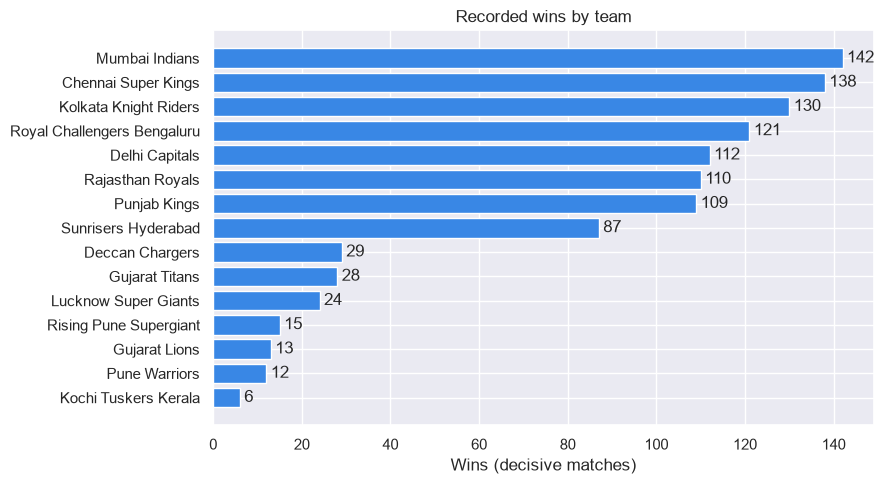

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
order = teams.sort_values("wins")
ax.barh(order["team"], order["wins"], color="#3987e5")
ax.set_xlabel("Wins (decisive matches)"); ax.set_title("Recorded wins by team")
for y, v in enumerate(order["wins"]):
    ax.text(v + 1, y, int(v), va="center")
plt.tight_layout(); plt.show()

## 13. Player performance analysis

In [14]:
bat = batting_stats(deliveries)
bat.head(10)

,batter,innings,runs,balls,fours,sixes,dismissals,highest_score,average,strike_rate
0,V Kohli,244,8004,6065,706,273,207,113,38.67,131.97
1,S Dhawan,221,6769,5324,768,153,192,106,35.26,127.14
2,RG Sharma,252,6628,5054,599,281,223,109,29.72,131.14
3,DA Warner,184,6565,4697,663,236,162,126,40.52,139.77
4,SK Raina,200,5528,4043,506,203,170,100,32.52,136.73
5,MS Dhoni,228,5243,3812,363,252,134,84,39.13,137.54
6,AB de Villiers,170,5162,3403,413,251,130,133,39.71,151.69
7,CH Gayle,141,4965,3333,405,357,125,175,39.72,148.96
8,RV Uthappa,197,4952,3799,481,182,180,88,27.51,130.35
9,KD Karthik,233,4842,3577,466,161,184,97,26.32,135.36


In [15]:
bowl = bowling_stats(deliveries)
print("Top wicket takers (wickets credited to the bowler, run outs excluded)")
bowl.head(10)

Top wicket takers (wickets credited to the bowler, run outs excluded)


,bowler,matches,legal_balls,runs_conceded,wickets,overs,economy,average,strike_rate
0,YS Chahal,159,3521,4602,205,586.5,7.84,22.45,17.18
1,PP Chawla,191,3850,5108,192,641.4,7.96,26.60,20.05
2,DJ Bravo,158,3120,4360,183,520.0,8.38,23.83,17.05
3,B Kumar,176,3910,4929,181,651.4,7.56,27.23,21.60
4,SP Narine,175,4075,4571,180,679.1,6.73,25.39,22.64
5,R Ashwin,208,4524,5369,180,754.0,7.12,29.83,25.13
6,A Mishra,162,3371,4145,174,561.5,7.38,23.82,19.37
7,SL Malinga,122,2828,3364,170,471.2,7.14,19.79,16.64
8,JJ Bumrah,133,3053,3715,165,508.5,7.30,22.52,18.50
9,RA Jadeja,211,3829,4864,160,638.1,7.62,30.40,23.93


In [16]:
qualified = bowl[bowl["legal_balls"] >= 500].sort_values("economy")
print("Best economy among bowlers with at least 500 legal balls (~83 overs)")
qualified.head(10)[["bowler", "matches", "overs", "runs_conceded", "wickets", "economy", "average", "strike_rate"]]

Best economy among bowlers with at least 500 legal balls (~83 overs)


,bowler,matches,overs,runs_conceded,wickets,economy,average,strike_rate
79,A Kumble,42,160.5,1058,45,6.58,23.51,21.44
58,M Muralitharan,66,254.0,1696,63,6.68,26.92,24.19
4,SP Narine,175,679.1,4571,180,6.73,25.39,22.64
119,DL Vettori,34,129.3,879,28,6.79,31.39,27.75
11,Rashid Khan,121,476.3,3252,149,6.82,21.83,19.19
130,J Botha,34,115.4,800,25,6.92,32.00,27.76
25,DW Steyn,95,362.4,2508,97,6.92,25.86,22.43
88,R Sharma,44,154.4,1086,40,7.02,27.15,23.20
101,MM Ali,52,126.2,893,35,7.07,25.51,21.66
10,Harbhajan Singh,160,569.2,4030,150,7.08,26.87,22.77


In [17]:
# Strike rate vs batting average for batters with a reasonable sample (>= 1000 balls faced)
sample = bat[bat["balls"] >= 1000]
fig = px.scatter(sample, x="average", y="strike_rate", size="runs", hover_name="batter",
                 title="Batters with 1000+ balls faced: average vs strike rate (bubble size = runs)")
fig.show()

In [18]:
# Correlation between a few batting measures (descriptive only, not causal)
sample[["runs", "balls", "average", "strike_rate", "fours", "sixes"]].corr().round(2)

,runs,balls,average,strike_rate,fours,sixes
runs,1.00,0.99,0.47,0.19,0.95,0.80
balls,0.99,1.00,0.43,0.05,0.95,0.72
average,0.47,0.43,1.00,0.24,0.41,0.42
strike_rate,0.19,0.05,0.24,1.00,0.10,0.55
fours,0.95,0.95,0.41,0.10,1.00,0.63
sixes,0.80,0.72,0.42,0.55,0.63,1.00


## 14. Toss analysis
Percentages use **decisive matches** (ties and no-result matches removed from the denominator). The results show an
**association**; they do not show that winning the toss causes a win.

In [19]:
tw = toss_win_match_win(matches)
print(f"Toss winner also won the match: {tw['toss_winner_won']} of {tw['decisive_matches']} decisive matches = {tw['pct']:.1f}%")
toss_decision_outcomes(matches)

Toss winner also won the match: 548 of 1076 decisive matches = 50.9%


,toss_decision,matches,toss_winner_won,toss_winner_lost,win_pct
0,bat,384,174,210,45.3
1,field,692,374,318,54.0


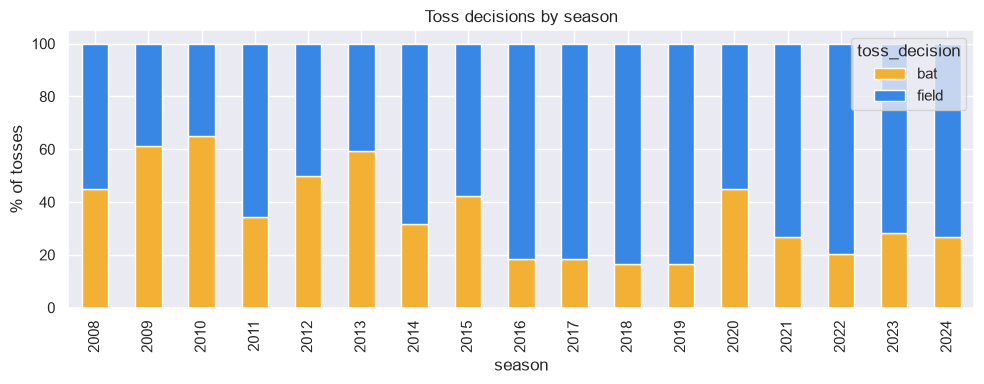

In [20]:
by_season = toss_decisions_by_season(matches)
pivot = by_season.pivot(index="season", columns="toss_decision", values="share_pct").fillna(0)
pivot.plot(kind="bar", stacked=True, figsize=(10, 4), color=["#f2b134", "#3987e5"])
plt.ylabel("% of tosses"); plt.title("Toss decisions by season"); plt.tight_layout(); plt.show()

In [21]:
cd = chase_vs_defend(matches)
print(f"Won batting first: {cd['won_batting_first']} ({cd['batting_first_pct']:.1f}%)  |  "
      f"Won chasing: {cd['won_chasing']} ({cd['chasing_pct']:.1f}%)  |  decisive matches: {cd['decisive_matches']}")
# Batting order comes from the ball-by-ball data, so we can check it against the toss decision:
check = matches.assign(toss_winner_batted_first=matches["toss_winner"] == matches["batting_first"])
pd.crosstab(check["toss_decision"], check["toss_winner_batted_first"])

Won batting first: 492 (45.7%)  |  Won chasing: 584 (54.3%)  |  decisive matches: 1076


toss_winner_batted_first,False,True
toss_decision,,
bat,0,391
field,704,0


## 15. Venue analysis

In [22]:
venues = venue_summary(matches)
venues.head(10)

,venue,city,matches,seasons_used,avg_first_innings,highest_total,decisive,batting_first_wins,chasing_wins,batting_first_win_pct
0,"Wankhede Stadium, Mumbai",Mumbai,118,14,170.3,235.0,117,53.0,64.0,45.3
1,"M Chinnaswamy Stadium, Bengaluru",Bangalore,94,13,173.2,287.0,90,41.0,49.0,45.6
2,"Eden Gardens, Kolkata",Kolkata,93,14,166.3,262.0,93,38.0,55.0,40.9
3,"Arun Jaitley Stadium, Delhi",Delhi,90,14,169.3,266.0,88,43.0,45.0,48.9
4,"MA Chidambaram Stadium, Chepauk, Chennai",Chennai,85,11,163.9,246.0,83,47.0,36.0,56.6
5,"Rajiv Gandhi International Stadium, Uppal, Hyd...",Hyderabad,77,12,162.8,277.0,76,34.0,42.0,44.7
6,"Punjab Cricket Association IS Bindra Stadium, ...",Chandigarh,61,12,168.3,257.0,61,27.0,34.0,44.3
7,"Sawai Mansingh Stadium, Jaipur",Jaipur,57,9,161.5,217.0,57,20.0,37.0,35.1
8,"Maharashtra Cricket Association Stadium, Pune",Pune,51,7,162.4,211.0,51,28.0,23.0,54.9
9,Dubai International Cricket Stadium,Dubai,46,3,163.8,219.0,43,21.0,22.0,48.8


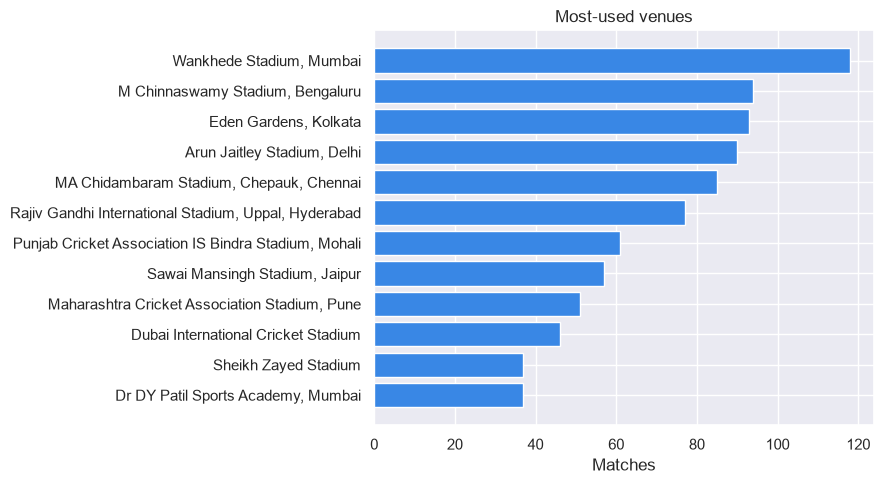

In [23]:
top = venues.head(12).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top["venue"], top["matches"], color="#3987e5")
plt.xlabel("Matches"); plt.title("Most-used venues"); plt.tight_layout(); plt.show()

Match counts alone do not show that a venue favours batters or bowlers. The `batting_first_win_pct` column needs its sample size (`decisive`) next to it.

## 16. Season analysis

In [24]:
ov = season_overview(matches)
ov

,season,matches,teams,venues,avg_first_innings
0,2008,58,8,9,161.0
1,2009,57,8,8,150.3
2,2010,60,8,12,164.8
3,2011,73,10,12,152.4
4,2012,74,9,12,157.5
5,2013,76,9,12,155.9
6,2014,60,8,13,163.1
7,2015,59,8,13,166.3
8,2016,60,8,11,162.6
9,2017,59,8,10,165.8


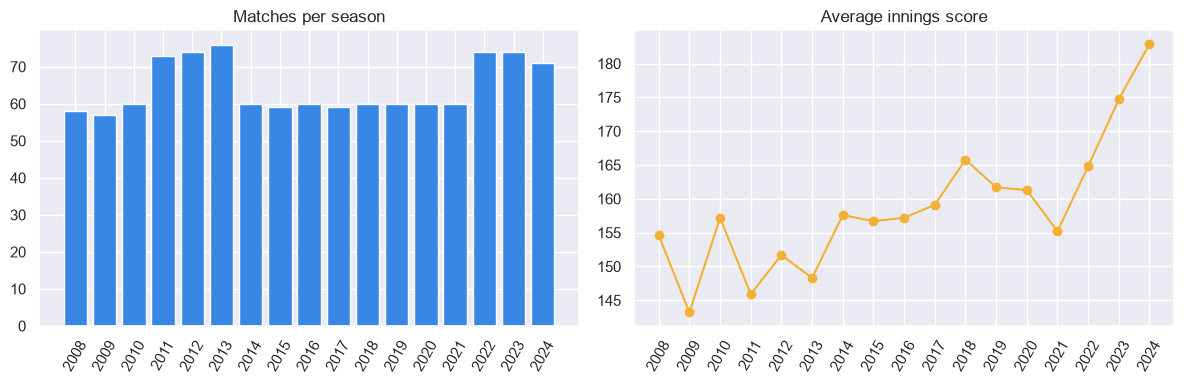

In [25]:
runs = season_runs(deliveries, matches)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(ov["season"].astype(str), ov["matches"], color="#3987e5"); axes[0].set_title("Matches per season")
axes[0].tick_params(axis="x", rotation=60)
axes[1].plot(runs["season"].astype(str), runs["avg_innings_score"], marker="o", color="#f2b134")
axes[1].set_title("Average innings score"); axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

In [26]:
season_leaders(matches, deliveries)

,season,top_run_scorer,runs,top_wicket_taker,wickets
0,2008,SE Marsh,616,Sohail Tanvir,22
1,2009,ML Hayden,572,RP Singh,23
2,2010,SR Tendulkar,618,PP Ojha,21
3,2011,CH Gayle,608,SL Malinga,28
4,2012,CH Gayle,733,M Morkel,25
5,2013,MEK Hussey,733,DJ Bravo,32
6,2014,RV Uthappa,660,MM Sharma,23
7,2015,DA Warner,562,DJ Bravo,26
8,2016,V Kohli,973,B Kumar,23
9,2017,DA Warner,641,B Kumar,26


## 17. Visualizations

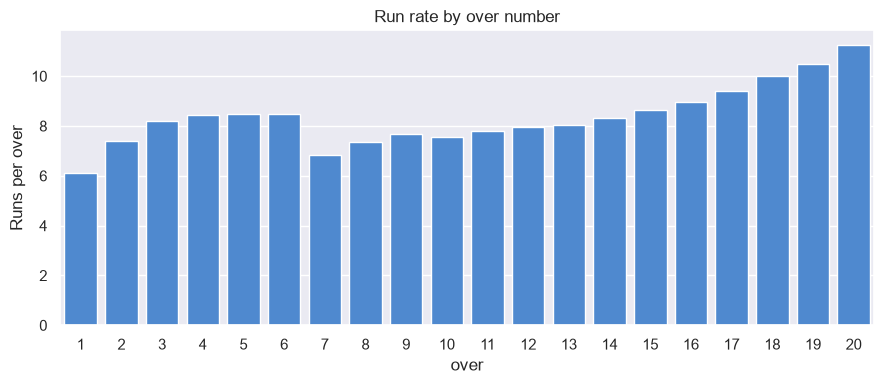

In [27]:
# Run rate in each over of the innings (powerplay = overs 1-6)
ro = runs_by_over(deliveries)
plt.figure(figsize=(9, 4))
sns.barplot(data=ro, x="over", y="run_rate", color="#3987e5")
plt.title("Run rate by over number"); plt.ylabel("Runs per over"); plt.tight_layout(); plt.show()

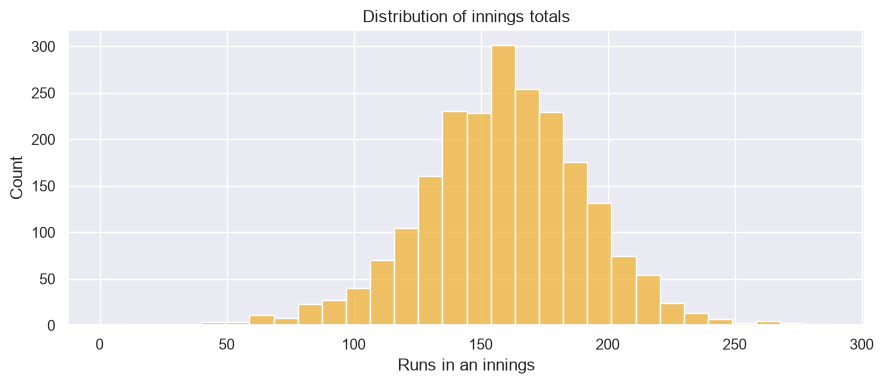

In [28]:
# Distribution of innings totals (histogram)
plt.figure(figsize=(9, 4))
sns.histplot(innings.values, bins=30, color="#f2b134")
plt.xlabel("Runs in an innings"); plt.title("Distribution of innings totals"); plt.tight_layout(); plt.show()

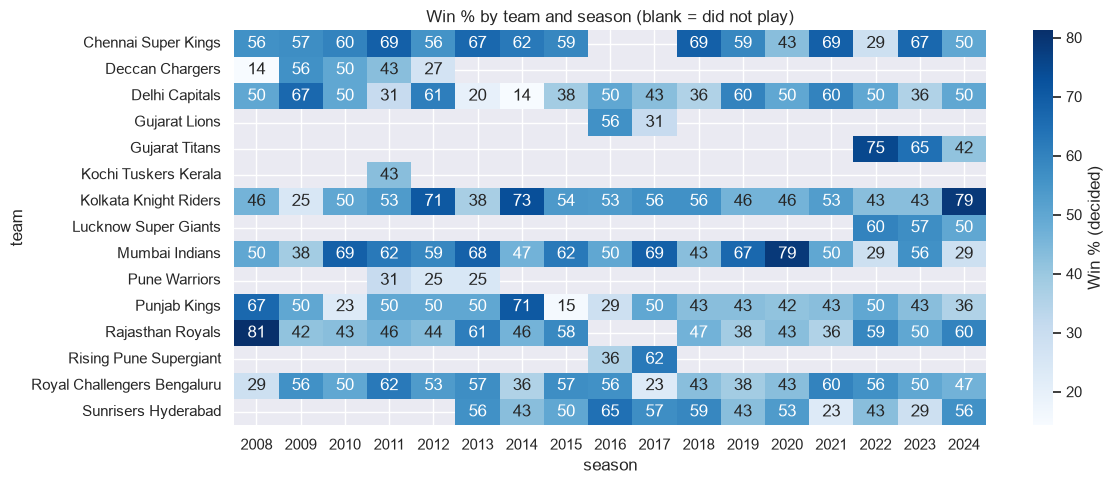

In [29]:
# Win % of decided matches for each team, season by season (heat map)
st = season_team_summary(matches)
heat = st.pivot(index="team", columns="season", values="win_pct_decided")
plt.figure(figsize=(12, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Win % (decided)"})
plt.title("Win % by team and season (blank = did not play)"); plt.tight_layout(); plt.show()

In [30]:
dis = dismissal_types(deliveries)
px.bar(dis, x="dismissal_kind", y="wickets", color="credited_to_bowler", title="Dismissals by type").show()

## 18. Findings (computed from the data above)

In [31]:
t = teams.iloc[0]; b = bat.iloc[0]; w = bowl.iloc[0]; v = venues.iloc[0]
best_sr = bat[bat["balls"] >= 500].sort_values("strike_rate", ascending=False).iloc[0]
pom = player_of_match_counts(matches).iloc[0]
print(f"* Most wins: {t['team']} with {int(t['wins'])} wins in {int(t['matches'])} matches.")
print(f"* Most runs: {b['batter']} with {int(b['runs'])} runs in {int(b['innings'])} innings.")
print(f"* Most wickets: {w['bowler']} with {int(w['wickets'])}.")
print(f"* Highest strike rate (500+ balls faced): {best_sr['batter']} at {best_sr['strike_rate']:.1f}.")
print(f"* Most Player of the Match awards: {pom['player']} ({int(pom['awards'])}).")
print(f"* Busiest venue: {v['venue']} with {int(v['matches'])} matches.")
print(f"* Toss winner won the match {tw['pct']:.1f}% of the time ({tw['decisive_matches']} decisive matches).")
print(f"* Teams batting second won {cd['chasing_pct']:.1f}% of decisive matches.")

* Most wins: Mumbai Indians with 142 wins in 261 matches.
* Most runs: V Kohli with 8004 runs in 244 innings.
* Most wickets: YS Chahal with 205.
* Highest strike rate (500+ balls faced): AD Russell at 174.9.
* Most Player of the Match awards: AB de Villiers (25).
* Busiest venue: Wankhede Stadium, Mumbai with 118 matches.
* Toss winner won the match 50.9% of the time (1076 decisive matches).
* Teams batting second won 54.3% of decisive matches.


## 19. Limitations
* The results describe **this dataset only**; they may differ slightly from official IPL records.
* Super overs are excluded from batting and bowling statistics. Tied matches are not counted as wins.
* Fours and sixes are deliveries where the bat scored exactly 4 or 6; the data cannot separate a run-four from a boundary.
* Franchise renames are merged, but Deccan Chargers / Sunrisers Hyderabad and similar pairs are treated as different teams.
* Toss and chase results are observed patterns with modest sample sizes in some cases; they are not predictions or causes.
* Fielding contributions (catches, run-outs) and player roles are not analysed.

## 20. Conclusion
Using a documented cleaning pipeline we turned two raw CSV files into reliable team, player, toss, venue and season
statistics. The headline figures are printed in the Findings section above and can be reproduced in the Streamlit app.
The same functions power both the notebook and the app, so there is a single definition of every metric.